In [17]:
import POSEIDON
import numpy as np
import pickle
import spectres
from tqdm import tqdm
from POSEIDON.core import (create_star,create_planet,define_model,make_atmosphere,compute_spectrum,
                           read_opacities, wl_grid_constant_R)
from POSEIDON.constants import R_J, R_Sun ,M_J
from POSEIDON.chemistry import load_chemistry_grid
import scipy.constants as sc
import matplotlib.pyplot as plt

In [18]:
spectra_eq = np.load('equi_chem_data/eq_chemistry_spectra.npy')
params_eq = np.load('equi_chem_data/eq_chemistry_params.npy')
wl_binned = np.load('free_chem_data/wl_binned.npy')

In [19]:
params_eq

array([[ 7.34027961e-01,  1.23745112e+00,  7.89256662e-01,
         1.31125832e+03,  2.80285723e+00,  1.51758910e+00],
       [ 5.30876741e-01,  1.44533790e+00,  4.84988025e+00,
         4.56825753e+02,  2.46470458e+00,  1.28200702e+00],
       [ 9.56363364e-01,  4.48468569e-01,  2.62900984e+00,
         2.54759513e+03, -1.50643557e-01,  5.27284941e-01],
       ...,
       [ 1.49118613e+00,  1.99049363e+00,  2.27938447e+00,
         7.74251966e+02,  2.36938647e+00,  1.11134530e+00],
       [ 1.51977895e+00,  8.41306520e-01,  2.72142453e+00,
         2.29743867e+03,  2.84100234e+00,  9.52153538e-01],
       [ 1.30475181e+00,  6.08002877e-01,  4.25270759e+00,
         2.82293034e+03,  2.89847412e+00,  1.24644547e+00]])

In [20]:
params_names_eq = ['Rstar_Rs', 'Rp_Rj', 'Mp_Mj', 'T', 'log_Met', 'C_to_O']

print(f"Spectra shape: {spectra_eq.shape}")
print(f"Params shape: {params_eq.shape}")
print(f"Wavelength bins: {len(wl_binned)}")

Spectra shape: (113176, 52)
Params shape: (113176, 6)
Wavelength bins: 52


## Plot1 : Parameter Distribution

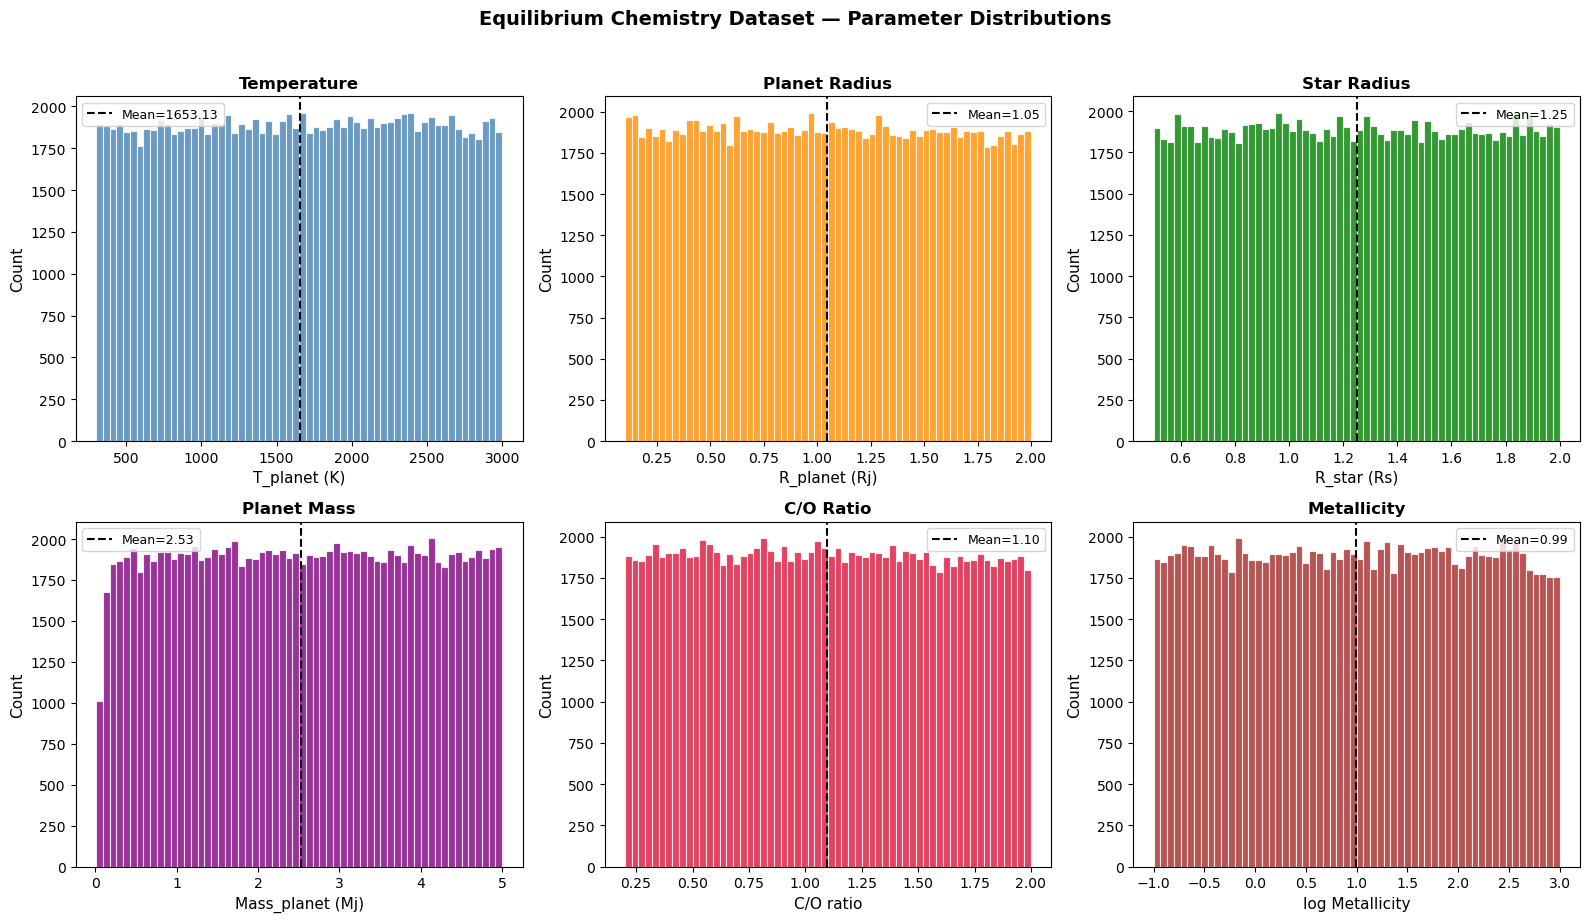

In [21]:
fig,axes = plt.subplots(2,3,figsize=(16,9))
axes = axes.flatten()

plot_config = [
 (3, 'T_planet (K)','Temperature', 'steelblue'),
 (1, 'R_planet (Rj)','Planet Radius',  'darkorange'),
 (0, 'R_star (Rs)',  'Star Radius', 'green'),
 (2, 'Mass_planet (Mj)','Planet Mass', 'purple'),
 (5, 'C/O ratio', 'C/O Ratio','crimson'),
 (4, 'log Metallicity', 'Metallicity', 'brown'),
]
for ax, (col_idx,xlabel,title,color) in zip(axes,plot_config):
    ax.hist(params_eq[:,col_idx],bins=60,color=color,edgecolor='white',alpha=0.8,linewidth = 0.8)
    ax.set_xlabel(xlabel,fontsize=11)
    ax.set_ylabel('Count',fontsize = 11)
    ax.set_title(title, fontsize=12, fontweight='bold')

    val = params_eq[:, col_idx]
    ax.axvline(val.mean(), color='black',linestyle='--', linewidth=1.5,label=f'Mean={val.mean():.2f}')
    ax.legend(fontsize=9)

plt.suptitle('Equilibrium Chemistry Dataset — Parameter Distributions',fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('diag_plot1_param_distributions.png',dpi=150, bbox_inches='tight')
plt.show()


In [22]:
param_species = ['H2O','CH4','CO','CO2','NH3']
bulk_species = ['H2','He']
chemistry_grid = load_chemistry_grid(param_species,grid='fastchem')
P = np.logspace(np.log10(10.0), np.log10(1e-7), 100)

Reading in database for equilibrium chemistry model...


In [26]:
np.random.seed(99)
sample_idx = np.random.choice(len(params_eq),10,replace='False')
vmr_profiles = []
sample_params = []

for idx in sample_idx:
    Rstar_Rs, Rp_Rj, Mp_Mj, T, log_Met, C_to_O = params_eq[idx]
    R_p = Rp_Rj*R_J
    M_p = Mp_Mj*M_J
    R_s = Rstar_Rs*R_Sun
    g_p = (sc.G * M_p) / (R_p ** 2)

    planet = create_planet('sample_planet',R_p,gravity=g_p,T_eq=T)
    model = define_model('sample_model',bulk_species,param_species,PT_profile='isotherm',X_profile='chem_eq')
    PT_params = np.array([T])
    X_params  = np.array([C_to_O, log_Met])

    atmosphere = make_atmosphere(planet,model,P,10.0,R_p,PT_params,X_params,chemistry_grid=chemistry_grid)

    vmr_dict = {}
    for mol in param_species:
        vmr_dict[mol] = atmosphere['X'][
            list(atmosphere['X'].keys()).index(mol)
            if mol in atmosphere['X'] else 0
        ]

    vmr_profiles.append(atmosphere)
    sample_params.append(params_eq[idx])

print(f"Regenerated {len(vmr_profiles)} atmosphere objects")
print(f"Atmosphere keys: {list(vmr_profiles[0].keys())}")

Regenerated 10 atmosphere objects
Atmosphere keys: ['P', 'T', 'g', 'n', 'r', 'r_up', 'r_low', 'dr', 'P_surf', 'X', 'X_active', 'X_CIA', 'X_ff', 'X_bf', 'mu', 'N_sectors', 'N_zones', 'alpha', 'beta', 'phi', 'theta', 'phi_edge', 'theta_edge', 'dphi', 'dtheta', 'kappa_cloud_0', 'P_cloud', 'f_cloud', 'phi_cloud_0', 'theta_cloud_0', 'a', 'gamma', 'is_physical', 'mu_back', 'H', 'r_m', 'log_n_max', 'fractional_scale_height', 'aerosol_species', 'r_i_real', 'r_i_complex', 'log_X_Mie', 'P_cloud_bottom', 'kappa_cloud_eddysed', 'g_cloud_eddysed', 'w_cloud_eddysed', 'log_r_m_std_dev', 'f_both', 'f_aerosol_1', 'f_aerosol_2', 'f_clear', 'albedo_deck', 'T_surf', 'albedo_surf', 'surface_component_percentages', 'R_p_ref']


Reading in database for equilibrium chemistry model...
Regenerating 10 atmospheres...
Done. Plotting...


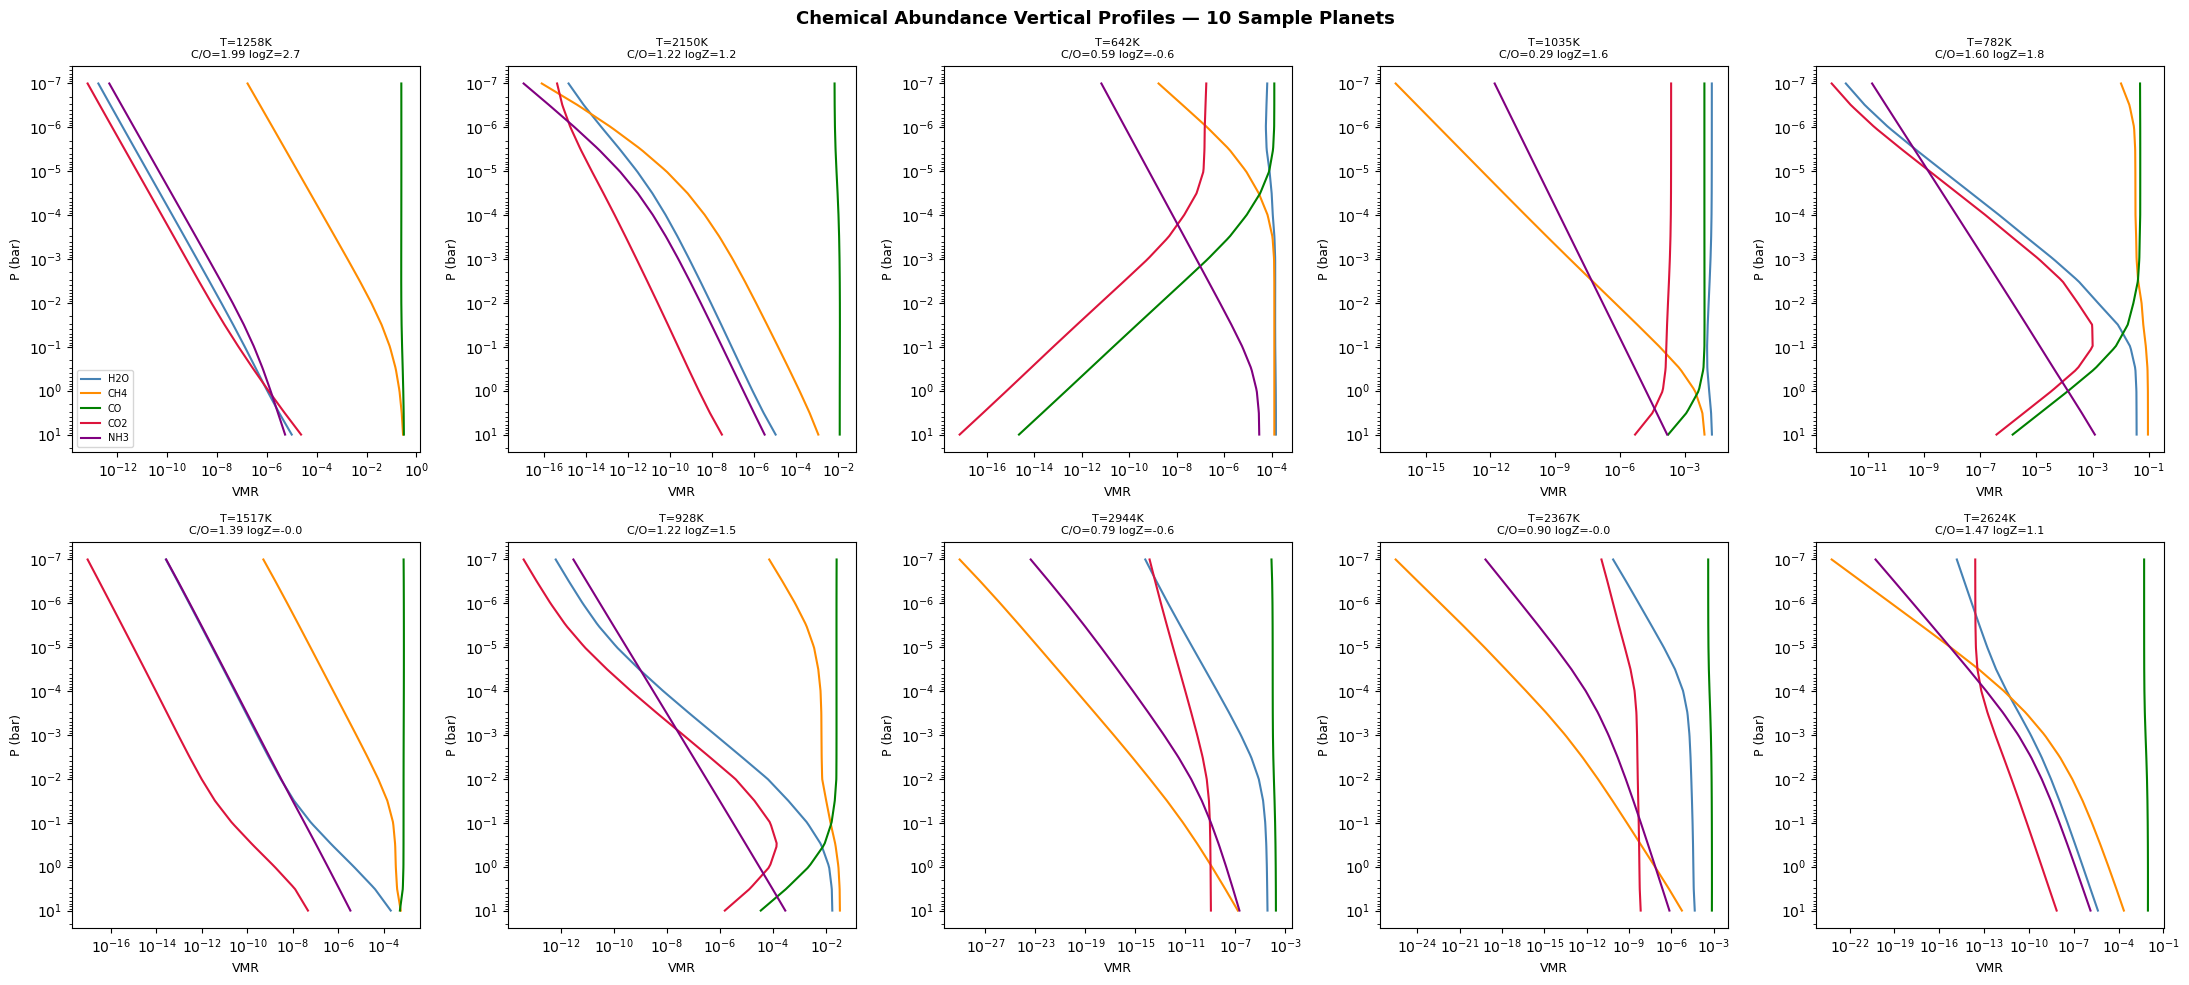

Plot 2 done


In [ ]:
# ── PLOT 2: Chemical abundance vertical profiles ──
from POSEIDON.core import create_planet, define_model, make_atmosphere
from POSEIDON.chemistry import load_chemistry_grid
from POSEIDON.constants import R_J, R_Sun, M_J
import scipy.constants as sc
import pickle

# Molecule info
mol_names   = ['H2O', 'CH4', 'CO',  'CO2',    'NH3']
mol_indices = [2,      3,     4,     5,         6   ]
mol_colors  = {
    'H2O': 'steelblue',
    'CH4': 'darkorange',
    'CO' : 'green',
    'CO2': 'crimson',
    'NH3': 'purple'
}

bulk_species  = ['H2', 'He']
param_species = ['H2O', 'CH4', 'CO', 'CO2', 'NH3']

# Pressure grid — same as generation
P = np.logspace(np.log10(10.0), np.log10(1e-7), 100)

# Load chemistry grid
chemistry_grid = load_chemistry_grid(param_species,
                                      grid='fastchem')

# Pick 10 random planets
np.random.seed(99)
sample_idx = np.random.choice(len(params_eq),
                               10, replace=False)

# Regenerate atmospheres for 10 planets
print("Regenerating 10 atmospheres...")
atm_list    = []
param_list  = []

for idx in sample_idx:
    Rstar_Rs, Rp_Rj, Mp_Mj, T, log_Met, C_to_O = \
        params_eq[idx]

    R_p = Rp_Rj   * R_J
    M_p = Mp_Mj   * M_J
    g_p = (sc.G * M_p) / (R_p ** 2)

    planet = create_planet('p', R_p,
                            gravity=g_p, T_eq=T)
    model  = define_model('m', bulk_species,
                           param_species,
                           PT_profile='isotherm',
                           X_profile='chem_eq')

    PT_params = np.array([T])
    X_params  = np.array([C_to_O, log_Met])

    atm = make_atmosphere(planet, model, P, 10.0,
                           R_p, PT_params, X_params,
                           chemistry_grid=chemistry_grid)
    atm_list.append(atm)
    param_list.append(params_eq[idx])

print("Done. Plotting...")

# Plot — 2 rows of 5 planets
fig, axes = plt.subplots(2, 5, figsize=(22, 10))

for planet_idx in range(10):
    row = planet_idx // 5
    col = planet_idx  % 5
    ax  = axes[row][col]

    atm = atm_list[planet_idx]
    par = param_list[planet_idx]

    for mol, mol_idx in zip(mol_names, mol_indices):
        # Extract VMR profile — shape (100,)
        vmr = atm['X'][mol_idx, :, 0, 0]

        # Replace zeros with tiny value for log plot
        vmr = np.where(vmr <= 0, 1e-30, vmr)

        ax.plot(vmr, P,
                color=mol_colors[mol],
                label=mol,
                linewidth=1.5)

    # Formatting
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.invert_yaxis()          # high altitude at top
    ax.set_xlabel('VMR',       fontsize=9)
    ax.set_ylabel('P (bar)',   fontsize=9)
    ax.set_title(
        f'T={par[3]:.0f}K\n'
        f'C/O={par[5]:.2f} '
        f'logZ={par[4]:.1f}',
        fontsize=8)

    if planet_idx == 0:
        ax.legend(fontsize=7, loc='lower left')

plt.suptitle(
    'Chemical Abundance Vertical Profiles'
    ' — 10 Sample Planets',
    fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('diag_plot2_vmr_profiles.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Plot 2 done")

In [28]:
# ── PLOT 3: VMR histograms at 100 mbar pressure level ──
# 100 mbar = 0.1 bar = 10^-1 bar
# We need ALL planets not just 10 — regenerate VMR at one pressure

# Find the pressure layer closest to 100 mbar in our grid
P_target = 0.1   # 100 mbar in bar
P_idx = np.argmin(np.abs(P - P_target))
print(f"Using pressure layer {P_idx}: P = {P[P_idx]:.4f} bar "
      f"(target was 0.1 bar)")

# Regenerate VMRs at this pressure level for ALL planets
# This is faster than full atmosphere — use vectorized FASTCHEM lookup
# Use the chemistry grid directly

vmr_at_100mbar = {mol: [] for mol in param_species}

print("Extracting VMRs at 100 mbar for all planets...")
for i in range(len(params_eq)):
    Rstar_Rs, Rp_Rj, Mp_Mj, T, log_Met, C_to_O = params_eq[i]

    R_p = Rp_Rj * R_J
    M_p = Mp_Mj * M_J
    g_p = (sc.G * M_p) / (R_p**2)

    planet = create_planet('p', R_p, gravity=g_p, T_eq=T)
    model  = define_model(f'm_{i}', bulk_species, param_species,
                           PT_profile='isotherm',
                           X_profile='chem_eq')

    PT_params = np.array([T])
    X_params  = np.array([C_to_O, log_Met])

    atm = make_atmosphere(planet, model, P, 10.0, R_p,
                           PT_params, X_params,
                           chemistry_grid=chemistry_grid)

    # Extract VMR at P_idx for each molecule
    # (update key after seeing atmosphere keys)
    for mol in param_species:
        vmr_at_100mbar[mol].append(atm['X'][mol][P_idx])

    if i % 10000 == 0:
        print(f"  {i}/{len(params_eq)}")

# Convert to arrays
for mol in param_species:
    vmr_at_100mbar[mol] = np.array(vmr_at_100mbar[mol])

print("Done extracting VMRs")

Using pressure layer 25: P = 0.0955 bar (target was 0.1 bar)
Extracting VMRs at 100 mbar for all planets...


IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

NameError: name 'vmr_at_100mbar' is not defined

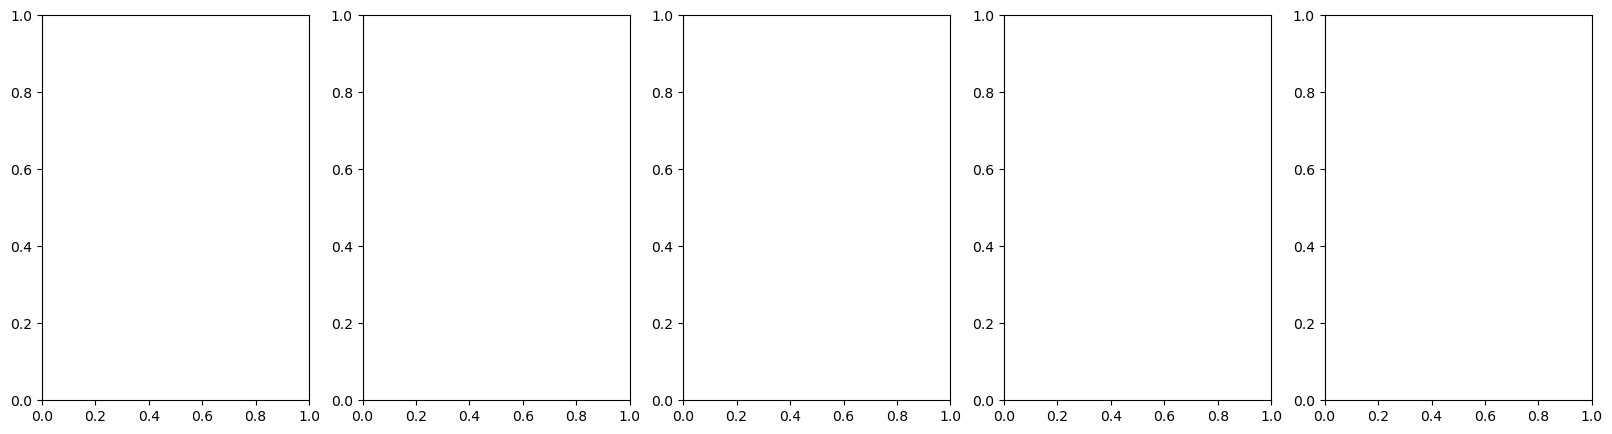

In [27]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, mol in zip(axes, param_species):
    vmr_vals = np.log10(vmr_at_100mbar[mol])
    vmr_vals = vmr_vals[np.isfinite(vmr_vals)]
    ax.hist(vmr_vals, bins=60,color=mol_colors[mol],edgecolor='white', alpha=0.85,linewidth=0.3)
    ax.set_xlabel(f'log VMR', fontsize=11)
    ax.set_ylabel('Count', fontsize=11)
    ax.set_title(f'{mol} at 100 mbar',fontsize=12, fontweight='bold')

    # Stats
    ax.axvline(vmr_vals.mean(), color='black',linestyle='--', linewidth=1.5,label=f'Mean={vmr_vals.mean():.2f}')
    ax.legend(fontsize=9)

plt.suptitle('VMR Distributions at 100 mbar Pressure Level',fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('diag_plot3_vmr_histograms.png',dpi=150, bbox_inches='tight')
plt.show()
print("Plot 3 done")

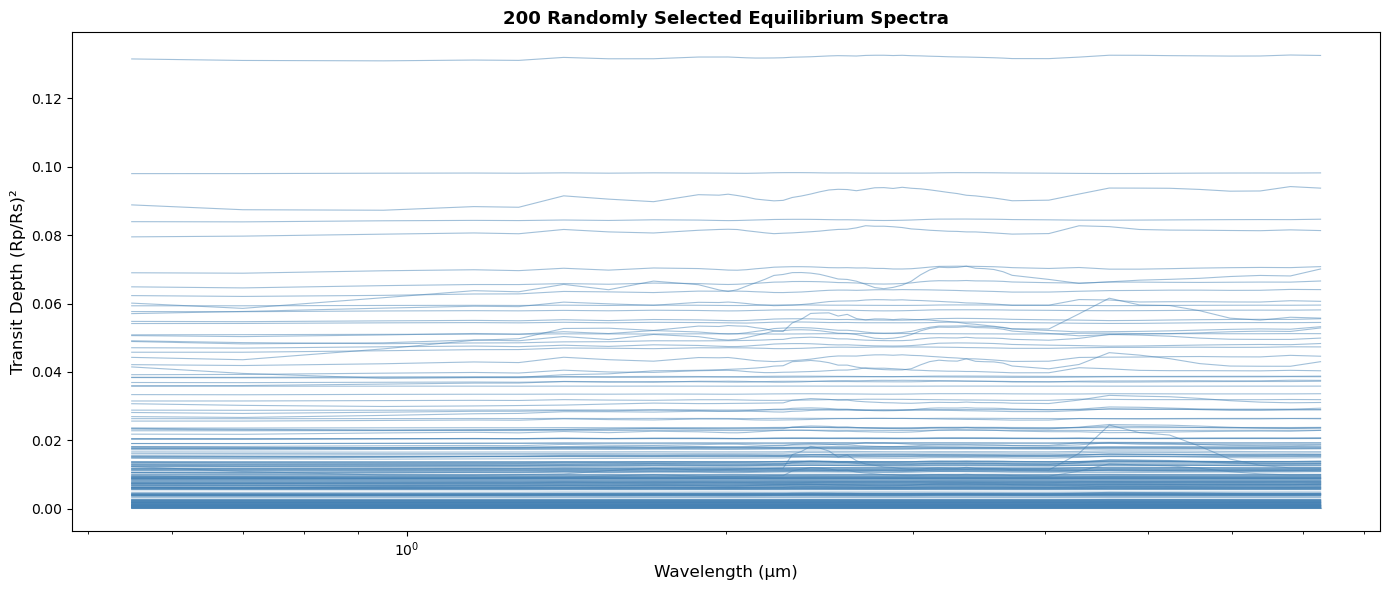

Plot 4 done


In [ ]:
np.random.seed(7)
idx_200 = np.random.choice(len(spectra_eq), 200, replace=False)

fig, ax = plt.subplots(figsize=(14, 6))
for i in idx_200:
    ax.plot(wl_binned, spectra_eq[i],alpha=0.5, linewidth=0.8,color='steelblue')

ax.set_xlabel('Wavelength (μm)', fontsize=12)
ax.set_ylabel('Transit Depth (Rp/Rs)²', fontsize=12)
ax.set_title('200 Randomly Selected Equilibrium Spectra',fontsize=13, fontweight='bold')
ax.set_xscale('log')
plt.tight_layout()
plt.savefig('diag_plot4_200_spectra.png',dpi=150, bbox_inches='tight')
plt.show()
print("Plot 4 done")

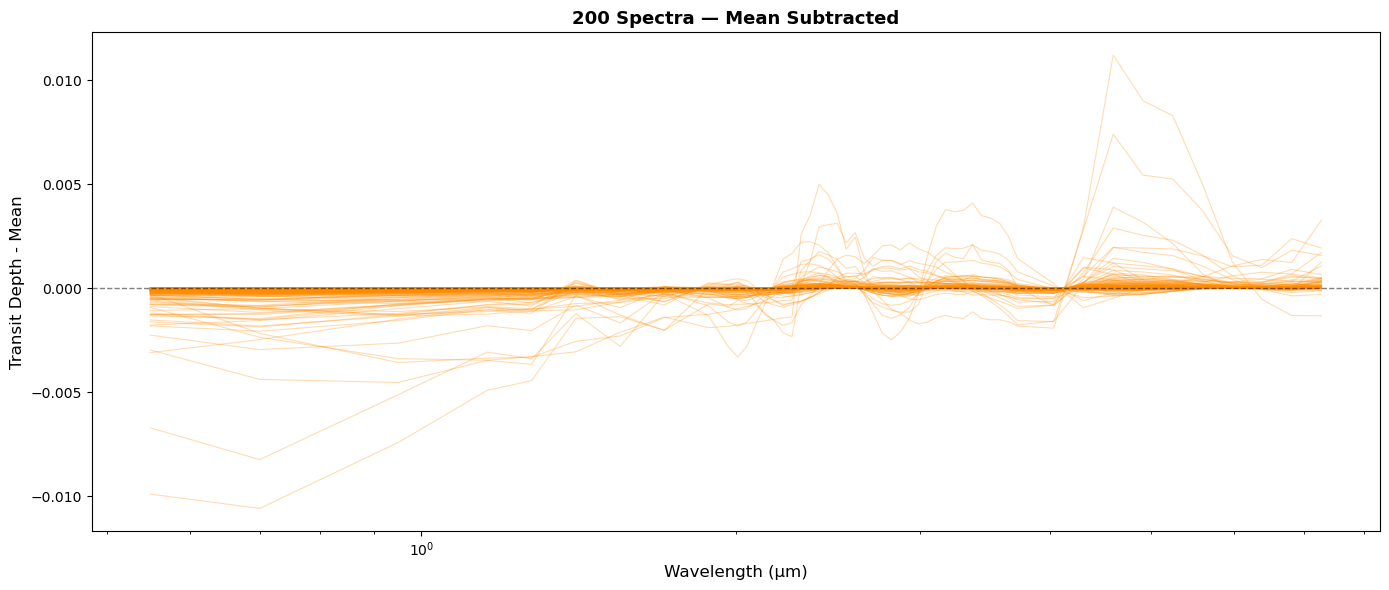

Plot 5 done


In [ ]:
fig, ax = plt.subplots(figsize=(14, 6))

for i in idx_200:
    spec = spectra_eq[i]
    spec_centred = spec - spec.mean()
    ax.plot(wl_binned, spec_centred,alpha=0.3, linewidth=0.8,color='darkorange')

ax.axhline(0, color='black', linewidth=1,linestyle='--', alpha=0.5)
ax.set_xlabel('Wavelength (μm)', fontsize=12)
ax.set_ylabel('Transit Depth - Mean', fontsize=12)
ax.set_title('200 Spectra — Mean Subtracted',fontsize=13, fontweight='bold')
ax.set_xscale('log')
plt.tight_layout()
plt.savefig('diag_plot5_mean_centred.png',dpi=150, bbox_inches='tight')
plt.show()
print("Plot 5 done")

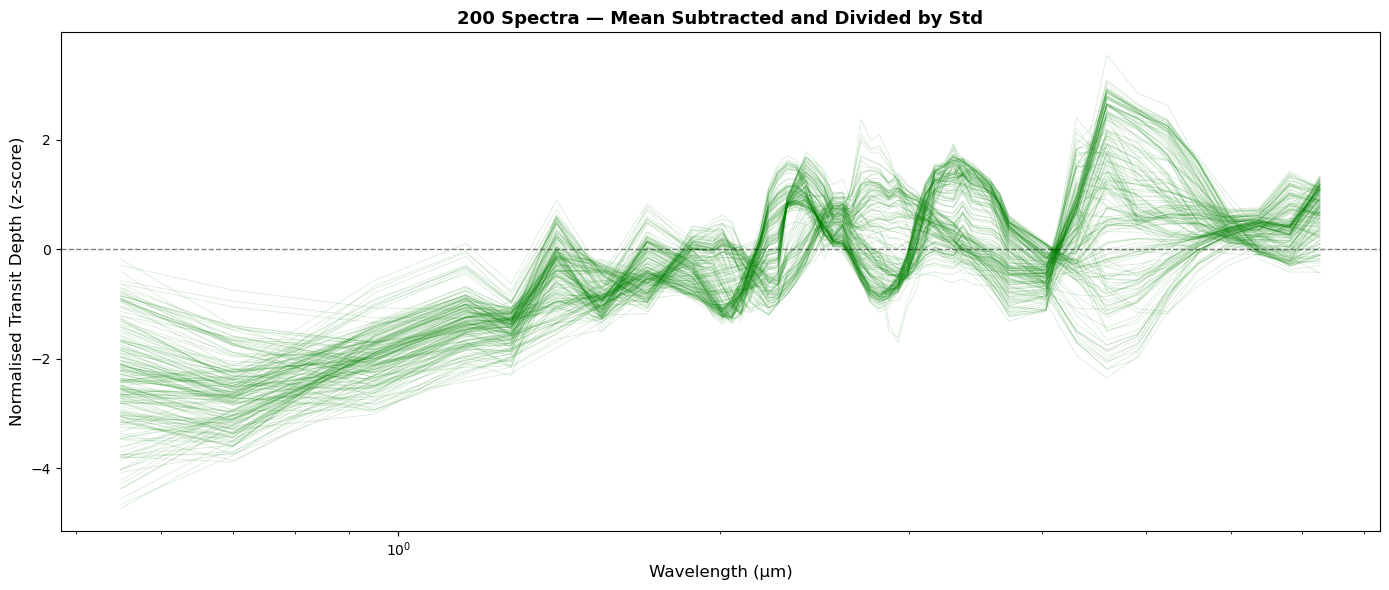

Plot 6 done


In [ ]:
fig, ax = plt.subplots(figsize=(14, 6))

for i in idx_200:
    spec = spectra_eq[i]
    spec_norm = (spec - spec.mean()) / spec.std()  # z-score normalise
    ax.plot(wl_binned, spec_norm,
            alpha=0.15, linewidth=0.6,
            color='green')

ax.axhline(0, color='black', linewidth=1,linestyle='--', alpha=0.5)
ax.set_xlabel('Wavelength (μm)', fontsize=12)
ax.set_ylabel('Normalised Transit Depth (z-score)', fontsize=12)
ax.set_title('200 Spectra — Mean Subtracted and Divided by Std',fontsize=13, fontweight='bold')
ax.set_xscale('log')
plt.tight_layout()
plt.savefig('diag_plot6_zscore_spectra.png',dpi=150, bbox_inches='tight')
plt.show()
print("Plot 6 done")

Total spectra:           113176
Spectra with depth > 1:  0
Percentage:              0.000%


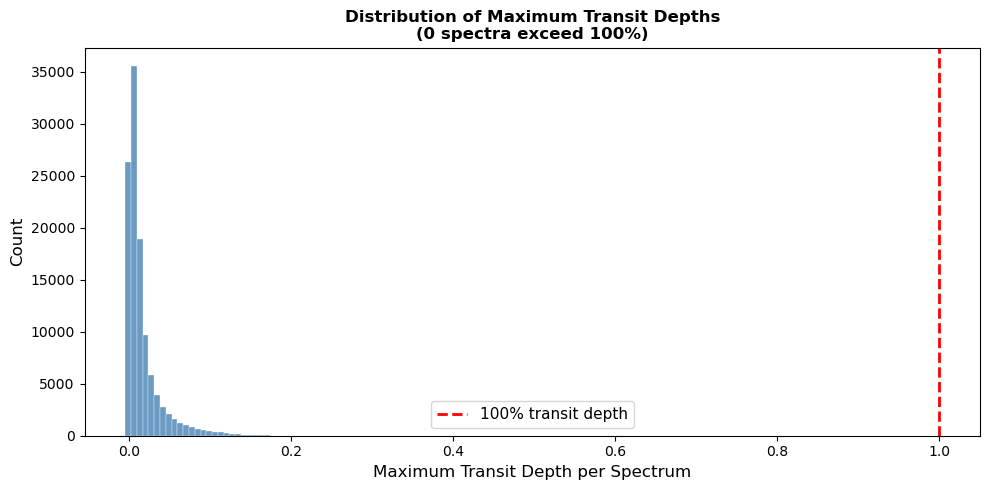


Plot 7 done — 0 unphysical spectra found
All spectra are physically valid — no cleaning needed


In [ ]:
# ── PLOT 7: Check for unphysical spectra ─────
# Transit depth > 1.0 means planet appears bigger than star
# That is physically impossible

max_depth_per_spectrum = spectra_eq.max(axis=1)
bad_mask = max_depth_per_spectrum > 1.0
n_bad = bad_mask.sum()

print(f"Total spectra:           {len(spectra_eq)}")
print(f"Spectra with depth > 1:  {n_bad}")
print(f"Percentage:              {n_bad/len(spectra_eq)*100:.3f}%")

if n_bad > 0:
    print(f"\nMax depth in bad spectra: "f"{max_depth_per_spectrum[bad_mask].max():.4f}")
    print(f"Parameters of bad spectra:")
    bad_params = params_eq[bad_mask]
    for row in bad_params[:5]:
        print(f"  Rstar={row[0]:.2f} Rp={row[1]:.2f} "
              f"Mp={row[2]:.2f} T={row[3]:.0f} "
              f"logMet={row[4]:.2f} C/O={row[5]:.2f}")

# Plot distribution of max depths
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(max_depth_per_spectrum, bins=100,color='steelblue', edgecolor='white',alpha=0.8, linewidth=0.3)
ax.axvline(1.0, color='red', linewidth=2,linestyle='--', label='100% transit depth')
ax.set_xlabel('Maximum Transit Depth per Spectrum', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title('Distribution of Maximum Transit Depths\n'f'({n_bad} spectra exceed 100%)',fontsize=12, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('diag_plot7_transit_depth_check.png',dpi=150, bbox_inches='tight')
plt.show()
print(f"\nPlot 7 done — {n_bad} unphysical spectra found")

# Remove bad spectra if any
if n_bad > 0:
    spectra_eq_clean = spectra_eq[~bad_mask]
    params_eq_clean  = params_eq[~bad_mask]
    print(f"Clean dataset: {len(spectra_eq_clean)} spectra")
    np.save('eq_chemistry_spectra_clean.npy', spectra_eq_clean)
    np.save('eq_chemistry_params_clean.npy',  params_eq_clean)
    print("Saved clean dataset")
else:
    print("All spectra are physically valid — no cleaning needed")
    spectra_eq_clean = spectra_eq
    params_eq_clean  = params_eq

In [ ]:
atm = vmr_profiles[0]
print(type(atm['X']))
if hasattr(atm['X'], 'keys'):
    print(list(atm['X'].keys()))
else:
    print(atm['X'].shape)

<class 'numpy.ndarray'>
(7, 100, 1, 1)


In [ ]:
atm = vmr_profiles[0]
model_check = define_model('check', ['H2','He'],
                            ['H2O','CH4','CO','CO2','NH3'],
                            PT_profile='isotherm',
                            X_profile='chem_eq')

print("Chemical species order:")
for i, sp in enumerate(model_check['chemical_species']):
    print(f"  Index {i}: {sp}")

Chemical species order:
  Index 0: H2
  Index 1: He
  Index 2: H2O
  Index 3: CH4
  Index 4: CO
  Index 5: CO2
  Index 6: NH3
